# From choreography video to floor map

We wanted to see where the dancers were on the floor throughout the choreography. This notebook follows the decisions from the source video through the 300-image replay. Run the cells in order to inspect the saved experiments on CPU. The outputs are saved for reading on GitHub.

[Open the final 0.30 replay](Experiment/lighting_expansion_300/runs/lighting_300_visual_s17/joint_evaluation/lighting_trial_replay.mp4) · [Detailed experiments](Research_Notebook.ipynb) · [Retraining commands](Experiment/lighting_expansion_300/REPRODUCE.md)

In [1]:
from collections import Counter
from pathlib import Path
import json
import xml.etree.ElementTree as ET

from IPython.display import Image, Markdown, Video, display

root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "tools/run_notebooks.py").is_file())
exp = root / "Experiment"
early = exp / "Dance_Overnight"
trial_200 = exp / "lighting_expansion_200"
trial_300 = exp / "lighting_expansion_300"
run = trial_300 / "runs/lighting_300_visual_s17"
detector_run = trial_300 / "runs/detector_300_finetune_s17"
demo = run / "joint_evaluation"

def read(path):
    return json.loads(path.read_text(encoding="utf-8"))

def show(path, width=900):
    display(Image(filename=str(path), width=width))

def table(headers, rows):
    lines = [headers, ["---"] * len(headers), *rows]
    display(Markdown("\n".join("| " + " | ".join(map(str, row)) + " |" for row in lines)))

## 1. Start with the video

We chose the section with a fixed camera. The same floor calibration could then be used throughout the clip. The walkthrough uses frame 4450 as an example.

Source frames 3250–5673 · 96.96 seconds at 25 fps


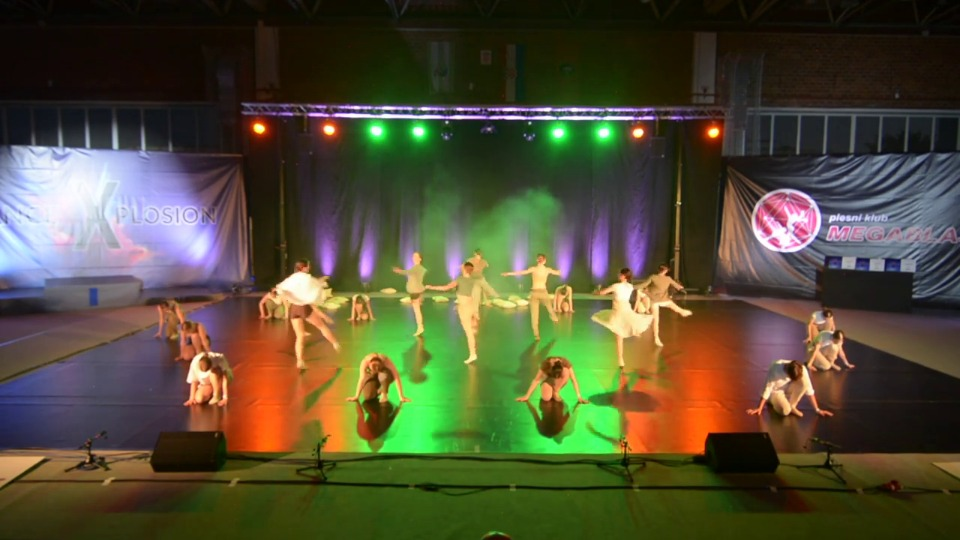

In [2]:
first, last, fps = 3250, 5673, 25
example = 4450
print(f"Source frames {first}–{last} · {(last - first + 1) / fps:.2f} seconds at {fps} fps")
show(trial_300 / "notebook_media/source_frame.jpg")

## 2. Find dancers and follow them

We used YOLO on overlapping crops to find small dancers near the back of the stage. We tried a detector trained on more lighting conditions and linked boxes across frames. The development check showed a small gain in correct IDs. Overlaps still caused gaps and switches.

Earlier detector · 100/120 boxes matched the original ID
Lighting-expanded detector · 101/120 boxes matched the original ID
Frame 4450 · 20 observed dancers, 0 carried forward


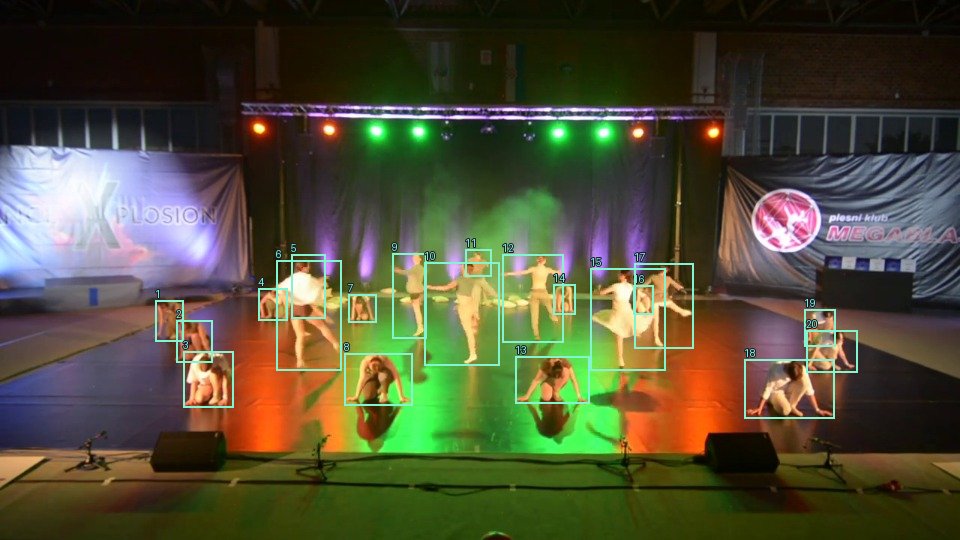

In [3]:
tracking = read(early / "detector_expanded/tracking_selection.json")
for key, name in [("baseline", "Earlier detector"), ("chosen", "Lighting-expanded detector")]:
    row = tracking[key]["validation"]
    print(f"{name} · {row['correct_initial_ids']}/{row['reference_boxes']} boxes matched the original ID")

tracks = read(early / "late_full_replay/base_tracks.json")["frames"]
statuses = Counter(row["status"] for row in tracks[example - first])
print(f"Frame {example} · {statuses['observed']} observed dancers, {statuses['predicted']} carried forward")
from PIL import Image as Photo, ImageDraw

with Photo.open(trial_300 / "notebook_media/source_frame.jpg") as source:
    overlay = source.copy()
draw = ImageDraw.Draw(overlay)
for row in tracks[example - first]:
    if row["status"] == "observed":
        box = tuple(round(value * 0.75) for value in row["box"])
        draw.rectangle(box, outline="#83f4ce", width=2)
        draw.text((box[0], box[1] - 12), str(row["id"]), fill="#83f4ce", stroke_width=1, stroke_fill="#171e2d")
display(overlay)

## 3. Find the point that touches the floor

We started with the bottom center of the box. It often missed the actual support when dancers knelt, sat, or used their hands. We trained a separate model to predict the support point and whether it was visible. We also tried neighboring frames and averaging models. Neither improved on its comparison model in the development checks, so we kept one model that reads one frame at a time.

| Approach | Visible contacts within 3% | Hidden marked visible |
| --- | --- | --- |
| Box geometry | 88/104 | 29 |
| Learned support | 99/104 | 4 |

Current frame · 72/77 within 3% in the separate temporal trial
Two frames · 72/77 within 3% in the separate temporal trial
Five frames · 72/77 within 3% in the separate temporal trial


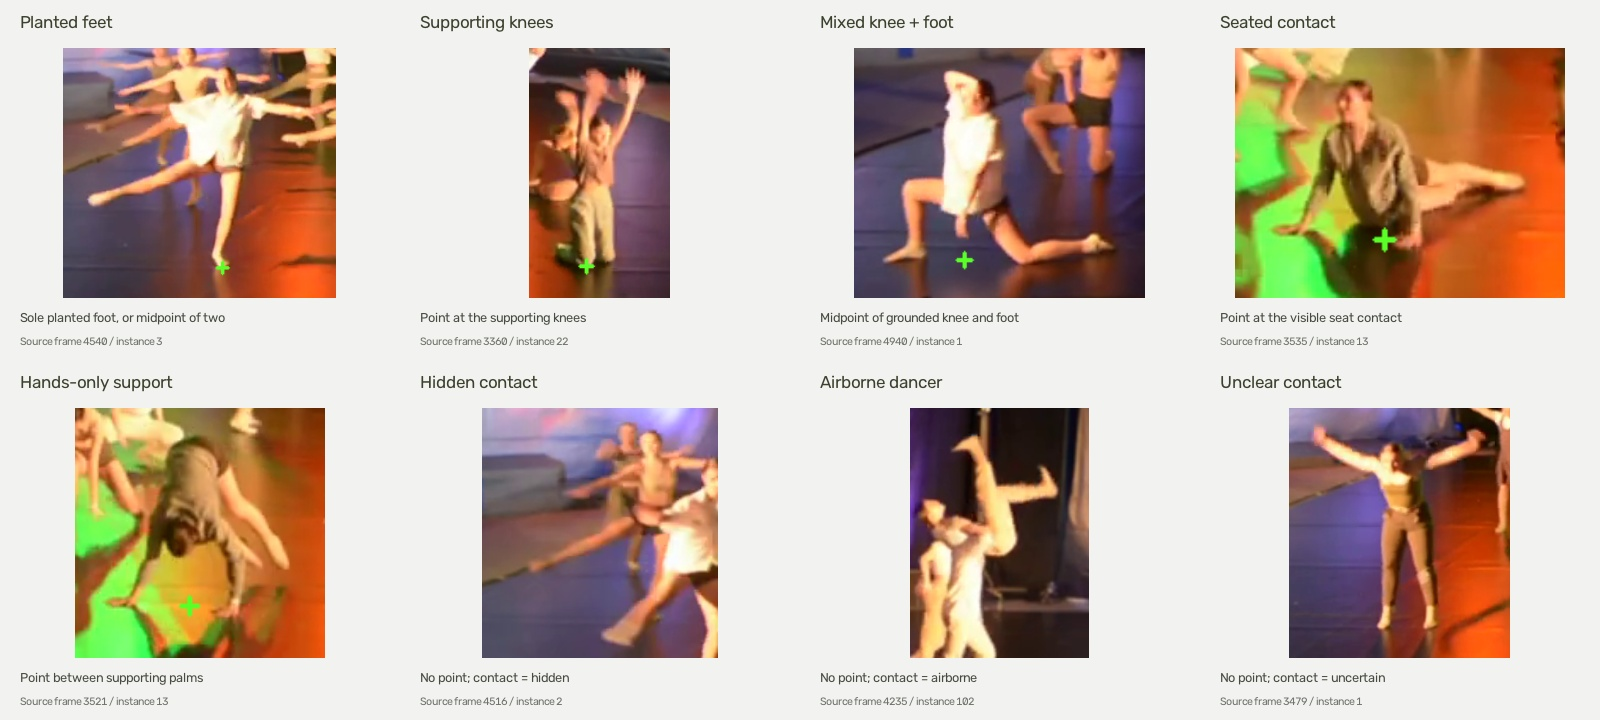

In [4]:
geometry = read(early / "geometry/results.json")["chosen"]["validation"]["selected"]
learned = read(early / "ending_experiment/results.json")["reference"]["old_development"]["selected"]
table(["Approach", "Visible contacts within 3%", "Hidden marked visible"], [
    [name, f"{row['correct']}/{row['refs']}", row["hidden_emitted"]]
    for name, row in [("Box geometry", geometry), ("Learned support", learned)]
])
temporal = read(early / "temporal_experiment/results.json")["runs"]
for key, name in [("v8_repeated_current_s17", "Current frame"), ("v8_temporal2_s17", "Two frames"), ("v8_temporal5_s17", "Five frames")]:
    score = temporal[key]["controlled_development"]["correct_by_tolerance_pct_width"]["3"]
    print(f"{name} · {score}/77 within 3% in the separate temporal trial")
show(early / "figures/label_examples.jpg")

## 4. Put the points on the map

We used the mat edges and guides to map image pixels to a top-down view. The offline trajectory fit reduced sudden jumps and estimated short gaps using nearby frames. Hollow dots in the replay mark those estimates.

In [5]:
calibration = read(exp / "Dance_CVAT_Pilot/calibration_draft.json")
matrix = calibration["pixel_to_relative_mat_homography"]

def project(point):
    homogeneous = [sum(a * b for a, b in zip(row, [*point, 1])) for row in matrix]
    x, y, scale = homogeneous
    return round(100 * x / scale, 2), round(62.5 * y / scale, 2)

corners = [project(point) for point in calibration["image_points"]]
print("Calibrated mat corners on the map", corners)
smooth = read(early / "round2/previous_test_diagnostic.json")["continuity"]
table(["Diagnostic replay", "Abrupt movement changes"], [
    ["Before offline fit", smooth["baseline"]["abrupt_changes_over_half_pct"]],
    ["After offline fit", smooth["candidate"]["abrupt_changes_over_half_pct"]],
])

Calibrated mat corners on the map [(0.0, 0.0), (100.0, -0.0), (100.0, 62.5), (0.0, 62.5)]


| Diagnostic replay | Abrupt movement changes |
| --- | --- |
| Before offline fit | 90 |
| After offline fit | 0 |

## 5. Label more of the choreography

We expanded from 60 training images to 200, then kept those labels and added 100. We sampled across lighting changes and dance poses, checked the proposed labels against the source, and corrected clipped boxes, missing dancers, and misplaced points. Each image has dancer boxes, visible support points where we could place them, and 12 floor guides. A, B, and C are review assignments. The annotations are assistant estimates with model-assisted proposals.

| Batch | Images | Dancer boxes | Visible support points |
| --- | --- | --- | --- |
| A | 100 | 1830 | 1331 |
| B | 100 | 1821 | 1360 |
| C | 100 | 1808 | 1377 |

3,600 floor guides · 497 unresolved contacts


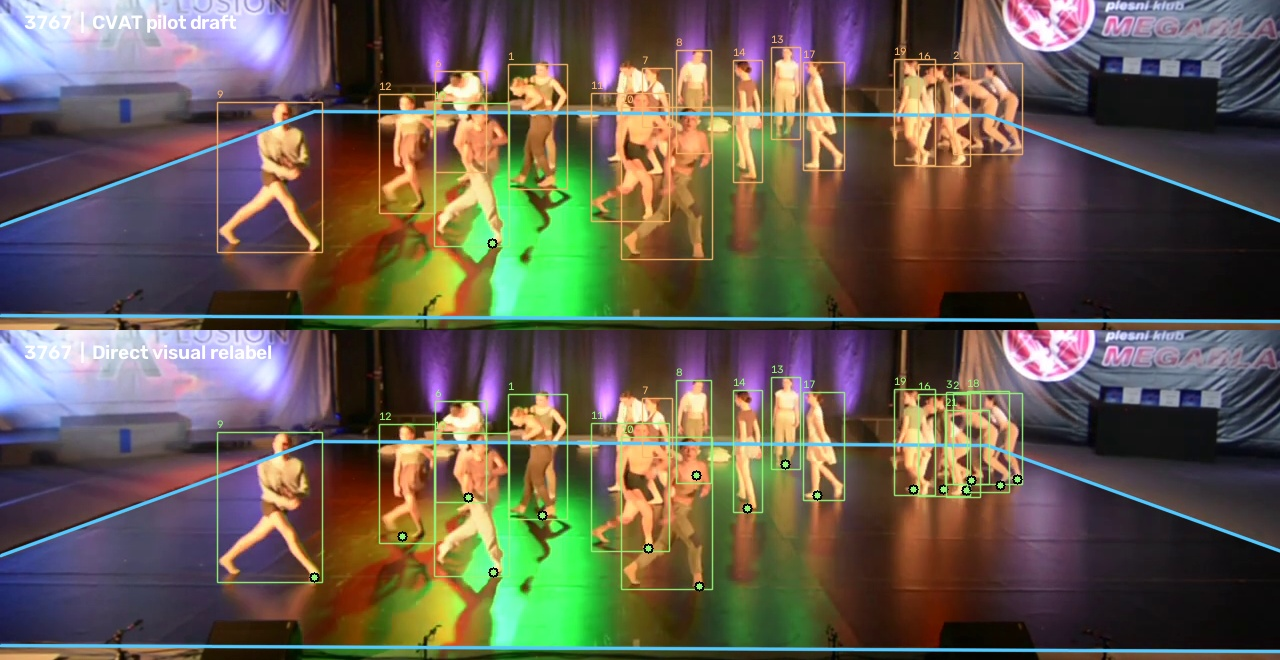

In [6]:
plan = read(trial_300 / "assignments.json")
groups = {}
rows = []
for batch in ("A", "B", "C"):
    images = ET.parse(trial_300 / f"{batch}.xml").findall("image")
    groups[batch] = {int(Path(image.attrib["name"]).stem.split("_")[-1]) for image in images}
    assert groups[batch] == set(plan["assignments"][batch]) and len(images) == 100
    rows.append([batch, len(images), sum(len(image.findall("box")) for image in images),
                 sum(len(image.findall("points")) for image in images)])
assert len(set.union(*groups.values())) == 300
table(["Batch", "Images", "Dancer boxes", "Visible support points"], rows)
qa = read(trial_300 / "structural_qa.json")
print(f"{qa['merged']['floor_polylines']:,} floor guides · {qa['merged']['contacts']['uncertain']} unresolved contacts")
show(trial_200 / "visual_relabel/3767_before_after.jpg")

## 6. Train on the revised labels

The support model learned from labeled contacts and known visibility. We excluded unresolved contacts from that training. We also fine-tuned the box detector on the 300 images. Both runs used the RTX 5080. We kept the original 11 validation images and used them to select checkpoints and calibrate the support threshold.

In [7]:
from csv import DictReader

manifest = read(trial_300 / "training_manifest.json")["lighting_300"]
assert not set(manifest["train"]) & set(manifest["val"])
assert not set(manifest["train"]) & set(range(3938, 4093))
history = read(run / "history.json")
best = max(history, key=lambda row: row["validation"]["selected"]["joint_f1"])
with (detector_run / "results.csv").open(encoding="utf-8") as file:
    detector_epochs = sum(1 for _ in DictReader(file))
selection = read(demo / "selection.json")
print(f"{len(manifest['train'])} training images · {len(manifest['val'])} validation images")
print(f"Support · {len(history)} epochs, selected epoch {best['epoch']}, scoring threshold {selection['threshold']:.2f}")
print(f"Detector · {detector_epochs} epochs")

300 training images · 11 validation images
Support · 30 epochs, selected epoch 17, scoring threshold 0.90
Detector · 15 epochs


## 7. Compare the models

On the seven reserved images, the published baseline still placed the most contacts within 3% of mat width. The 300-image detector and support model placed the most within 1% and made the fewest false reports on hidden contacts. The new detector also matched more reference boxes on the development images.

In [8]:
joint = read(demo / "results.json")
support = read(run / "evaluation/results.json")
variants = [
    ("Published baseline", joint["published_baseline"]["all"]),
    ("200 images", joint["revision_200"]["all"]),
    ("300 support, published detector", support["candidate_300_support"]["all"]),
    ("300 support and detector", joint["candidate_300_joint"]["all"]),
]
table(["Pipeline", "Within 1%", "Within 3%", "Hidden reported as visible"], [
    [name, f"{row['correct_by_tolerance_pct_width']['1']}/{row['visible_references']}",
     f"{row['correct_by_tolerance_pct_width']['3']}/{row['visible_references']}",
     f"{row['hidden_measured']}/{row['hidden_references']}"]
    for name, row in variants
])
for name, row in read(detector_run / "development_comparison.json")["models"].items():
    title = "Published detector" if name == "published_detector" else "300-image detector"
    print(f"{title} · {row['matched50']}/{row['references']} boxes matched at IoU 0.50")

| Pipeline | Within 1% | Within 3% | Hidden reported as visible |
| --- | --- | --- | --- |
| Published baseline | 11/46 | 29/46 | 5/50 |
| 200 images | 9/46 | 26/46 | 3/50 |
| 300 support, published detector | 13/46 | 28/46 | 3/50 |
| 300 support and detector | 14/46 | 27/46 | 2/50 |

Published detector · 158/197 boxes matched at IoU 0.50
300-image detector · 173/197 boxes matched at IoU 0.50


## 8. Show the finished floor map

We tried lowering the display threshold from 0.90 to 0.30 in the 200-image trial. The map gained dots with little change in measured jitter. We kept 0.30 for the 300-image demo. The scores above use validation-selected thresholds. The replay shows the result of combining the new detector and support model.

[Watch the final replay](Experiment/lighting_expansion_300/runs/lighting_300_visual_s17/joint_evaluation/lighting_trial_replay.mp4) · [Map coordinates](Experiment/lighting_expansion_300/runs/lighting_300_visual_s17/joint_evaluation/map_positions.json) · [Full 300-image results](Experiment/lighting_expansion_300/RESULTS.md)

| 200-image display threshold | Displayed dots |
| --- | --- |
| 0.90 | 28,153 |
| 0.75 | 30,997 |
| 0.60 | 32,893 |
| 0.50 | 33,990 |
| 0.40 | 34,693 |
| 0.30 | 35,596 |

300-image replay · 35,695 dots across 2,424 frames


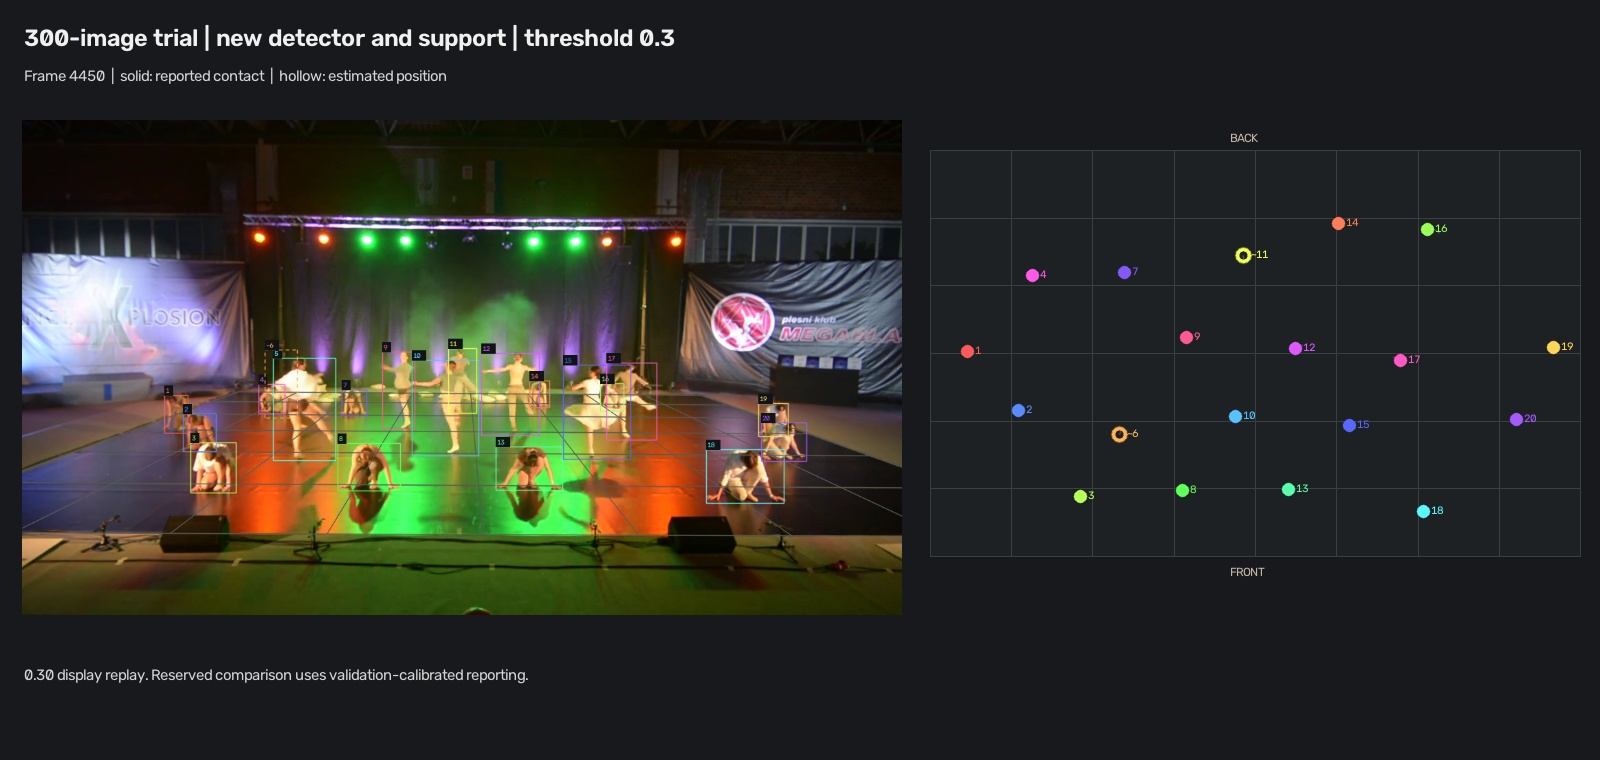

In [9]:
sweep = read(trial_200 / "runs/lighting_200_visual_s17/display_sweep.json")
table(["200-image display threshold", "Displayed dots"], [
    [f"{row['threshold']:.2f}", f"{row['displayed_dots']:,}"] for row in sweep
])
positions = read(demo / "map_positions.json")
dots = sum(map(len, positions["frames"]))
coverage = read(demo / "replay_coverage.json")
assert dots == coverage["displayed_dots"]
print(f"300-image replay · {dots:,} dots across {len(positions['frames']):,} frames")
show(demo / "replay_preview.jpg")
display(Video(url=(demo / "lighting_trial_replay.mp4").relative_to(root).as_posix(), width=900))

The next step is detecting formations from the exported map coordinates and measuring dancer placement within them.